# MSCS 634 – Lab 6: Association Rule Mining with Apriori and FP-Growth
**Name:** Umama Azhar

**Course:** MSCS 634 – Advanced Big Data and Data Mining

In [1]:
# Installing the libraries needed for this lab:
!pip install mlxtend openpyxl seaborn

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 23.0 MB/s  0:00:00
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)

  Attempting uninstall: matplotlib

    Found existing installation: matplotlib 3.10.7

   ---------------------------------------- 0/2 [matplotlib]
    Uninstalling matplotlib-3.10.7:
   ---------------------------------------- 0/2 [matplotlib]
   ---------------------------------------- 0/2 [matplotlib]
   ---------------------------------------- 0/2 [matplotlib]
   ---------------------------------------- 0/2 [matplotlib]
   ---------------------------------------- 0/2 [matplotlib]
   ---------------------------------------- 0/2 [matplotlib]
   ---------------------------------------- 0/2 [matplotlib]
   ---------------------------------------- 0/2 [matplotlib]
   --------------------------------------


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd

df = pd.read_csv(r'C:\Users\Umama\Downloads\data.csv\data.csv', encoding='ISO-8859-1')
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [6]:
# Removing rows with no product name, and tidying up the names
df = df.dropna(subset=['Description'])
df['Description'] = df['Description'].str.strip()

# Removing cancelled invoices (they start with 'C')
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.startswith('C')]

# Removing returns / bad rows
df = df[df['Quantity'] > 0]

print("Rows after cleaning:", len(df))
print("Unique invoices (baskets):", df['InvoiceNo'].nunique())
print("Unique products:", df['Description'].nunique())

Rows after cleaning: 530693
Unique invoices (baskets): 20136
Unique products: 4065


In [7]:
#Keeping only the baskets from one country so Apriori runs quickly

# Keeping only the rows where the Country column is 'France'
# (a smaller dataset means far fewer product combinations to check)
df_france = df[df['Country'] == 'France'].copy()

# Counting how many rows are left (each row is one product on one invoice)
print("Rows for France:", len(df_france))

# Counting unique invoice numbers = number of baskets (shopping trips)
print("Baskets (invoices):", df_france['InvoiceNo'].nunique())

# Counting unique product names = number of different items sold
print("Unique products:", df_france['Description'].nunique())

# Showing the first 5 rows to confirm the filter worked
df_france.head()

Rows for France: 8408
Baskets (invoices): 392
Unique products: 1563


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
26,536370,22728,ALARM CLOCK BAKELIKE PINK,24,12/1/2010 8:45,3.75,12583.0,France
27,536370,22727,ALARM CLOCK BAKELIKE RED,24,12/1/2010 8:45,3.75,12583.0,France
28,536370,22726,ALARM CLOCK BAKELIKE GREEN,12,12/1/2010 8:45,3.75,12583.0,France
29,536370,21724,PANDA AND BUNNIES STICKER SHEET,12,12/1/2010 8:45,0.85,12583.0,France
30,536370,21883,STARS GIFT TAPE,24,12/1/2010 8:45,0.65,12583.0,France


In [8]:
# Turning the list of purchases into a basket-by-product True/False grid

# Grouping rows by invoice (basket) and product, and adding up the Quantity.
# Result: one number for how many of each product were in each basket.
basket = df_france.groupby(['InvoiceNo', 'Description'])['Quantity'].sum()

# unstack() moves the product names from rows into columns,
# so each basket becomes one row and each product becomes one column.
basket = basket.unstack()

# Products not in a basket show up as empty (NaN), so fill those with 0
basket = basket.fillna(0)

# Converting the numbers to True/False: True if the product was bought (quantity > 0).
# Apriori and FP-Growth want this True/False format.
basket = basket > 0

# Showing the grid size: should be (number of baskets, number of products)
print("Grid shape:", basket.shape)

# Showing the top-left corner of the grid to check it looks right
basket.iloc[:5, :5]

Grid shape: (392, 1563)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 EGG HOUSE PAINTED WOOD,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND
InvoiceNo,,,,,
536370,False,False,False,False,False
536852,False,False,False,False,False
536974,False,False,False,False,False
537065,False,False,False,False,False
537463,False,False,False,False,False


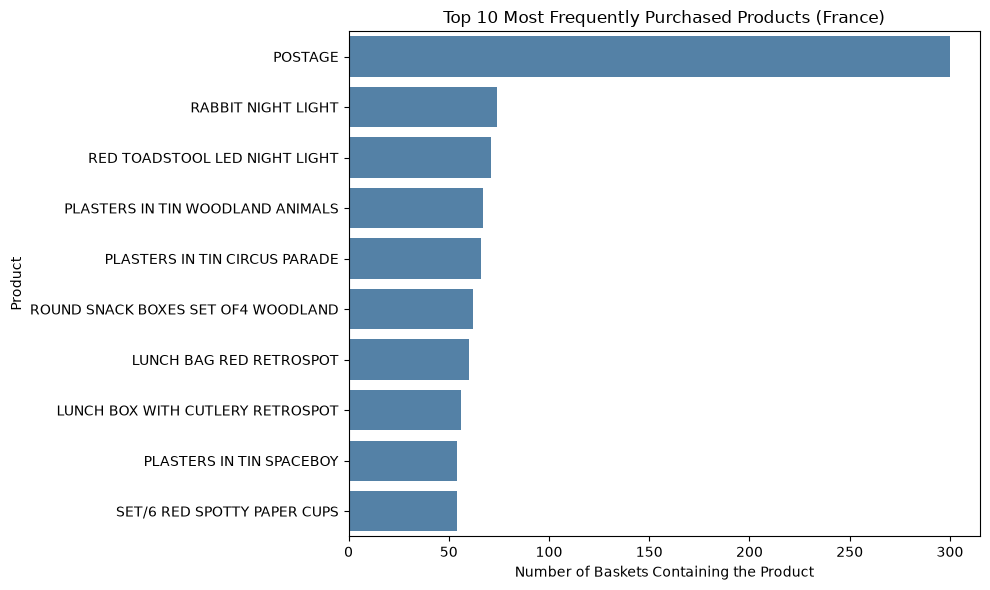

In [9]:
# Barplotting of the 10 products that appear in the most baskets

# Importing the plotting libraries (matplotlib draws, seaborn styles)
import matplotlib.pyplot as plt
import seaborn as sns

# Adding up the True values in each column = number of baskets containing that product.
# sort_values(ascending=False) puts the most common first; head(10) keeps the top 10.
top_items = basket.sum().sort_values(ascending=False).head(10)

# Turning the result into a small table with clear column names, so seaborn can plot it
top_items_df = top_items.reset_index()
top_items_df.columns = ['Product', 'Baskets']

# Making the figure wide enough to fit long product names
plt.figure(figsize=(10, 6))

# Drawing a horizontal bar chart: bar length = number of baskets, one bar per product
sns.barplot(data=top_items_df, x='Baskets', y='Product', color='steelblue')

# Adding a title and axis labels so the chart is easy to read
plt.title('Top 10 Most Frequently Purchased Products (France)')
plt.xlabel('Number of Baskets Containing the Product')
plt.ylabel('Product')

# tight_layout stops long labels from being cut off; show() displays the chart
plt.tight_layout()
plt.show()

Grid shape: (382, 1560)


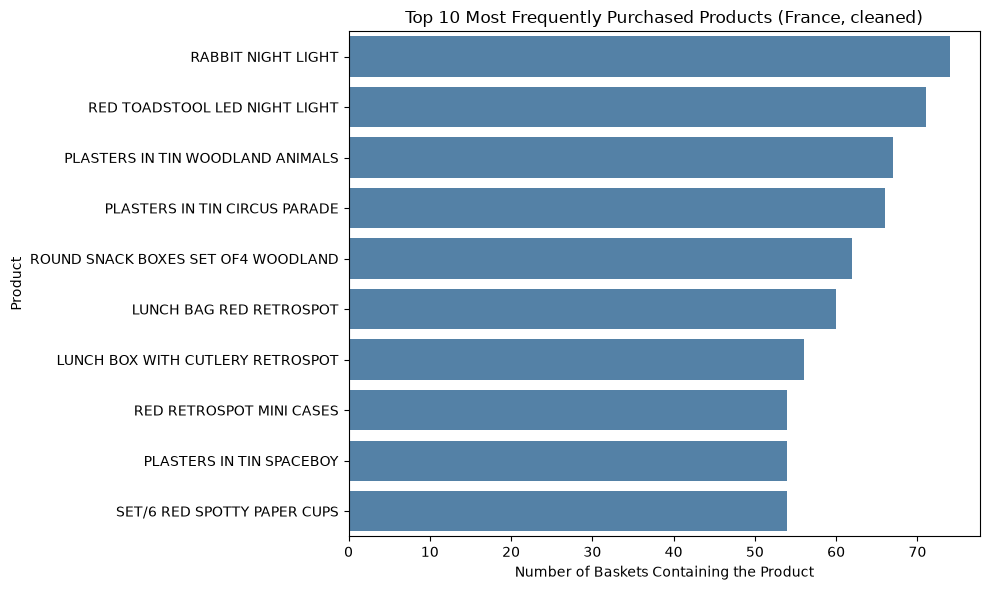

In [10]:
#Removing non-product rows (fees, shipping), rebuilding the grid, redrawing the chart

# List of "items" that are really fees or adjustments, not things customers shop for
non_products = ['POSTAGE', 'DOTCOM POSTAGE', 'CARRIAGE', 'Manual',
                'Discount', 'SAMPLES', 'AMAZON FEE', 'Bank Charges']

# Keeping only rows whose Description is NOT in that list
# (~ means "not", isin() checks membership in the list)
df_france = df_france[~df_france['Description'].isin(non_products)]

# Rebuilding the basket-by-product grid exactly as before:
# summing quantity per basket and product, spread products into columns,
# filling gaps with 0, then convert to True/False (True = product was bought)
basket = (df_france.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().fillna(0) > 0)

# Printing the new grid size to confirm one column (or a few) disappeared
print("Grid shape:", basket.shape)

# Counting baskets per product and keep the top 10, same as before
top_items = basket.sum().sort_values(ascending=False).head(10)
top_items_df = top_items.reset_index()
top_items_df.columns = ['Product', 'Baskets']

# Drawing the horizontal barplot again with the cleaned data
plt.figure(figsize=(10, 6))
sns.barplot(data=top_items_df, x='Baskets', y='Product', color='steelblue')
plt.title('Top 10 Most Frequently Purchased Products (France, cleaned)')
plt.xlabel('Number of Baskets Containing the Product')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

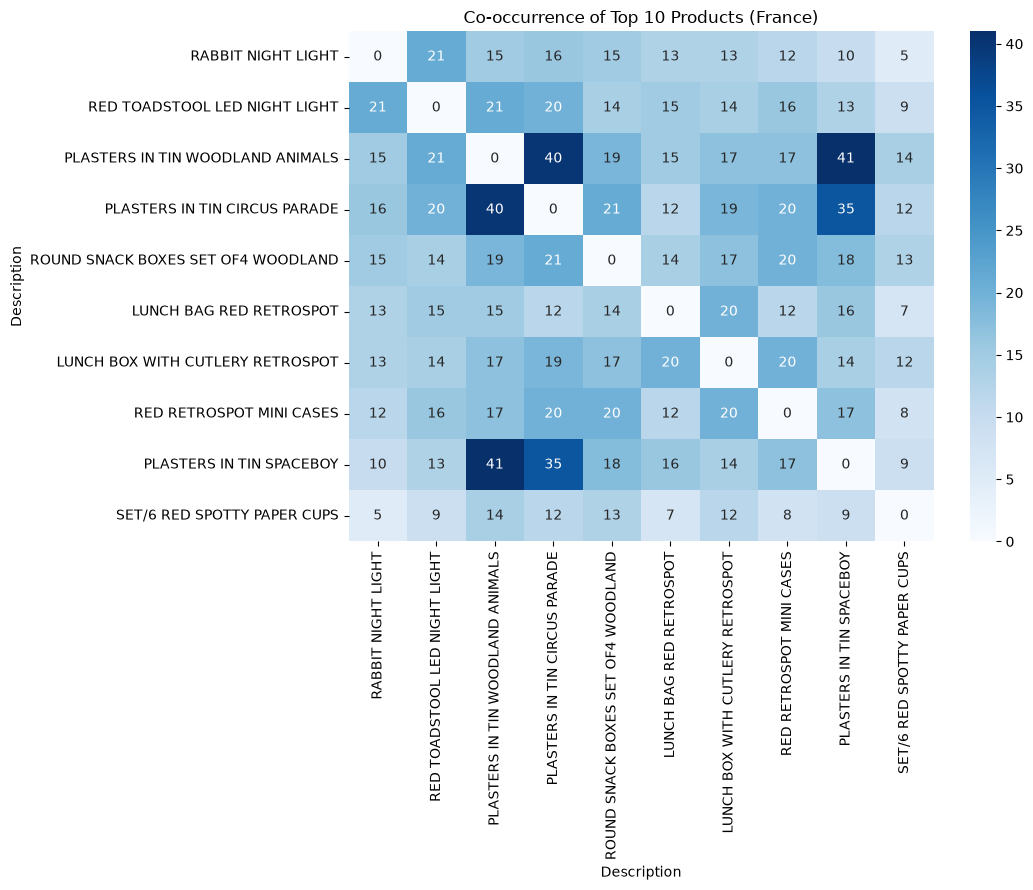

In [11]:
# Heatmap showing how often pairs of top products are bought together

# Picking the 10 most frequently bought products (their names), from the cleaned grid
top_names = basket.sum().sort_values(ascending=False).head(10).index

# Keeping only those 10 columns, and turn True/False into 1/0 so we can do math on it
top_basket = basket[top_names].astype(int)

# Matrix multiplication trick: (products x baskets) times (baskets x products).
# Each cell becomes the number of baskets where BOTH products appear.
cooccurrence = top_basket.T.dot(top_basket)

# The diagonal compares a product with itself (just its own basket count),
# so setting it to 0 so it doesn't drown out the real pair counts
for name in top_names:
    cooccurrence.loc[name, name] = 0

# Making a big figure so the long product names fit
plt.figure(figsize=(11, 9))

# Drawing the heatmap: annot=True prints the count in each cell,
# fmt='d' shows whole numbers, cmap sets the color scheme (darker = more together)
sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='Blues')

# Adding a title so the chart explains itself
plt.title('Co-occurrence of Top 10 Products (France)')

# Tidying the layout so labels aren't cut off, then display the chart
plt.tight_layout()
plt.show()

## Step 1: Data Preparation and Exploration

**What I did:** I loaded the Online Retail dataset (541,909 rows) and cleaned it by removing rows with no product name, cancelled invoices (invoice numbers starting with "C") and returns (negative quantities). That left 530,693 rows, 20,136 baskets and 4,065 products. To keep Apriori fast, I kept only the **France** baskets, then reshaped the data into a basket-by-product True/False grid, which is the format Apriori and FP-Growth need.

**Cleaning decision:** my first barplot showed that "POSTAGE" appeared in about 300 of 392 baskets. It is a shipping fee, not a product customers choose, so it would have created meaningless rules. I removed postage and other non-product rows, leaving 382 baskets and 1,560 products.

**What the charts show:**
- The cleaned barplot shows the most popular products, led by RABBIT NIGHT LIGHT (about 74 baskets) and RED TOADSTOOL LED NIGHT LIGHT.
- The co-occurrence heatmap shows that the three plasters tins are bought together most often: Spaceboy + Woodland Animals (41 baskets), Woodland Animals + Circus Parade (40) and Circus Parade + Spaceboy (35). This suggests the algorithms will find strong patterns among matching product sets.

In [12]:
#Finding frequent itemsets with the Apriori algorithm

# Importing Apriori from mlxtend, and time so I can measure how long it takes
from mlxtend.frequent_patterns import apriori
import time

# Minimum support: a group of products must appear in at least 5% of baskets.
# I am saving it in a variable so FP-Growth can use the exact same value later.
min_support = 0.05

# Starting the stopwatch just before running the algorithm
start = time.time()

# Running Apriori on the True/False grid.
# use_colnames=True shows real product names instead of column numbers.
frequent_apriori = apriori(basket, min_support=min_support, use_colnames=True)

# Stopping the stopwatch and calculating how many seconds Apriori took
apriori_time = time.time() - start

# Adding a column counting how many products are in each itemset (1, 2, 3...)
frequent_apriori['length'] = frequent_apriori['itemsets'].apply(len)

# Reporting the results: how long it took and how many itemsets it found
print("Apriori time (seconds):", round(apriori_time, 4))
print("Frequent itemsets found:", len(frequent_apriori))

# Showing the 10 itemsets with the highest support (most common groups)
frequent_apriori.sort_values('support', ascending=False).head(10)

Apriori time (seconds): 0.0278
Frequent itemsets found: 113


,support,itemsets,length
46,0.193717,(RABBIT NIGHT LIGHT),1
52,0.185864,(RED TOADSTOOL LED NIGHT LIGHT),1
44,0.175393,(PLASTERS IN TIN WOODLAND ANIMALS),1
40,0.172775,(PLASTERS IN TIN CIRCUS PARADE),1
59,0.162304,(ROUND SNACK BOXES SET OF4 WOODLAND),1
26,0.157068,(LUNCH BAG RED RETROSPOT),1
31,0.146597,(LUNCH BOX WITH CUTLERY RETROSPOT),1
42,0.141361,(PLASTERS IN TIN SPACEBOY),1
50,0.141361,(RED RETROSPOT MINI CASES),1
65,0.141361,(SET/6 RED SPOTTY PAPER CUPS),1


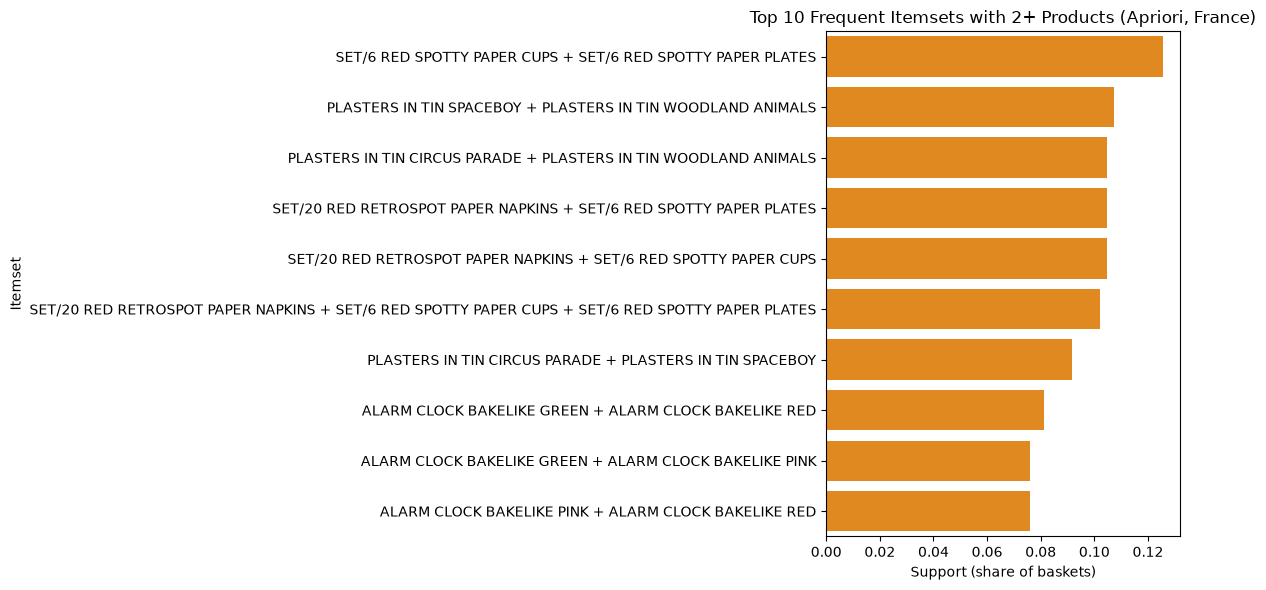

length
1    76
2    34
3     3
Name: count, dtype: int64


In [13]:
# Barplot of the top frequent itemsets that contain 2 or more products

# Keeping only itemsets with at least 2 products (single products aren't "associations")
multi_items = frequent_apriori[frequent_apriori['length'] >= 2].copy()

# Sorting by support (highest first) and keep the top 10
top_itemsets = multi_items.sort_values('support', ascending=False).head(10).copy()

# Itemsets are stored as sets, which can't be used as labels directly.
# Joining the product names with " + " so each bar has a readable label.
top_itemsets['itemset_label'] = top_itemsets['itemsets'].apply(lambda s: ' + '.join(sorted(s)))

# Making the figure wide because the labels (several product names) are long
plt.figure(figsize=(12, 6))

# Drawing a horizontal barplot: bar length = support (share of baskets containing the group)
sns.barplot(data=top_itemsets, x='support', y='itemset_label', color='darkorange')

# Adding a title and axis labels so the chart explains itself
plt.title('Top 10 Frequent Itemsets with 2+ Products (Apriori, France)')
plt.xlabel('Support (share of baskets)')
plt.ylabel('Itemset')

# Fitting labels inside the figure and display it
plt.tight_layout()
plt.show()

# Also printing how many frequent itemsets there are of each size (1, 2, 3...)
print(frequent_apriori['length'].value_counts().sort_index())

## Step 2: Frequent Itemsets with Apriori

**What I did:** I ran the Apriori algorithm on the France basket grid with a minimum support of **0.05**. This means a group of products counts as "frequent" only if it appears in at least 5% of baskets (roughly 20 of the 382 baskets). I chose 0.05 because the dataset is small: a higher threshold would find almost nothing, and a lower one would give too many weak patterns.

**What I found:** Apriori found **113 frequent itemsets**: 76 single products, 34 pairs and 3 triples. It ran in about 0.03 seconds.

**What the barplot shows:**
- The most common group is **SET/6 RED SPOTTY PAPER CUPS + SET/6 RED SPOTTY PAPER PLATES**, found together in about 12.5% of baskets.
- The plasters tins (Spaceboy, Woodland Animals, Circus Parade) also appear together often, matching the heatmap from Step 1.
-  Among the three-product groups are the red spotty party set (napkins, cups and plates) and the Bakelike alarm clocks (green, pink and red), which shows customers buy matching items together.
- The Bakelike alarm clocks in different colours also show up as pairs.

In [14]:
# Running FP-Growth with the same threshold and compare it with Apriori

# Importing FP-Growth from mlxtend
from mlxtend.frequent_patterns import fpgrowth

# Running FP-Growth once on the same True/False grid, using the SAME min_support as Apriori.
# use_colnames=True shows real product names.
frequent_fpgrowth = fpgrowth(basket, min_support=min_support, use_colnames=True)

# Adding the itemset size column (1, 2, 3...) like we did for Apriori
frequent_fpgrowth['length'] = frequent_fpgrowth['itemsets'].apply(len)

# Comparing the OUTPUT: how many itemsets did each algorithm find?
print("Apriori itemsets:   ", len(frequent_apriori))
print("FP-Growth itemsets: ", len(frequent_fpgrowth))

# Checking whether both found exactly the same itemsets.
# frozenset-of-itemsets lets us compare two lists ignoring their order.
same_itemsets = set(frequent_apriori['itemsets']) == set(frequent_fpgrowth['itemsets'])
print("Same itemsets found by both:", same_itemsets)

# Comparing the EFFICIENCY: time each algorithm over 20 runs for a fair average
runs = 20

# Time Apriori 20 times
start = time.time()
for _ in range(runs):
    apriori(basket, min_support=min_support, use_colnames=True)
apriori_avg = (time.time() - start) / runs

# Time FP-Growth 20 times
start = time.time()
for _ in range(runs):
    fpgrowth(basket, min_support=min_support, use_colnames=True)
fpgrowth_avg = (time.time() - start) / runs

# Printing the average time per run for each algorithm
print("Apriori average time (s):   ", round(apriori_avg, 4))
print("FP-Growth average time (s): ", round(fpgrowth_avg, 4))

# Showing how many times faster (or slower) FP-Growth was
print("Apriori / FP-Growth time ratio:", round(apriori_avg / fpgrowth_avg, 2))

Apriori itemsets:    113
FP-Growth itemsets:  113
Same itemsets found by both: True
Apriori average time (s):    0.0215
FP-Growth average time (s):  0.0337
Apriori / FP-Growth time ratio: 0.64


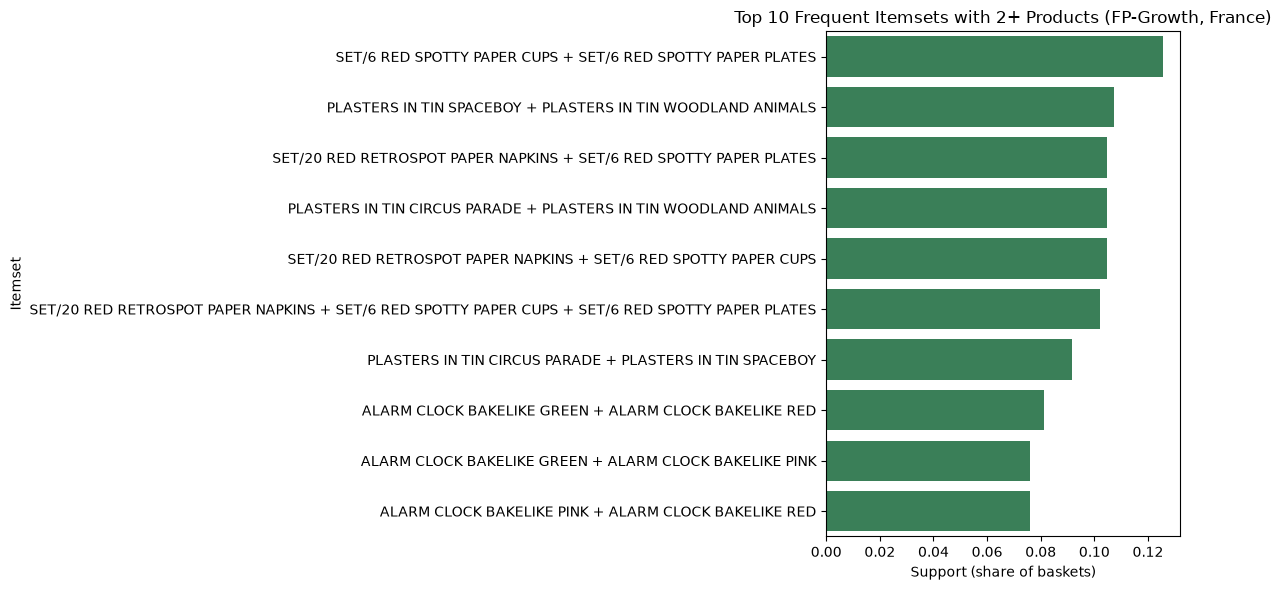

length
1    76
2    34
3     3
Name: count, dtype: int64


In [15]:
# Barplotting of the top FP-Growth itemsets with 2+ products

# Keeping only itemsets with at least 2 products (single products aren't "associations")
multi_fp = frequent_fpgrowth[frequent_fpgrowth['length'] >= 2].copy()

# Sorting by support (highest first) and keeping the top 10
top_fp = multi_fp.sort_values('support', ascending=False).head(10).copy()

# Turning each set of products into a readable label by joining names with " + "
top_fp['itemset_label'] = top_fp['itemsets'].apply(lambda s: ' + '.join(sorted(s)))

# Wide figure so the long labels fit
plt.figure(figsize=(12, 6))

# Drawing a horizontal barplot: bar length = support (share of baskets with the group)
sns.barplot(data=top_fp, x='support', y='itemset_label', color='seagreen')

# Title and axis labels so the chart explains itself
plt.title('Top 10 Frequent Itemsets with 2+ Products (FP-Growth, France)')
plt.xlabel('Support (share of baskets)')
plt.ylabel('Itemset')

# Fitting labels inside the figure and displaying it
plt.tight_layout()
plt.show()

# Printing how many itemsets there are of each size (1, 2, 3...) to compare with Apriori
print(frequent_fpgrowth['length'].value_counts().sort_index())

## Step 3: Frequent Itemsets with FP-Growth

**What I did:** I ran the FP-Growth algorithm on the same basket grid with the **same minimum support of 0.05** used for Apriori, so the two could be compared fairly. FP-Growth finds the same kind of frequent itemsets, but instead of testing many candidate combinations it first builds a compressed tree of the baskets and reads the patterns from that tree.

**Comparing the output:** FP-Growth found **113 frequent itemsets** (76 single products, 34 pairs and 3 triples), the same count as Apriori. A direct check confirmed that both algorithms found exactly the same itemsets.

**Comparing the efficiency:** because a single run takes only a few hundredths of a second, I averaged 20 runs of each algorithm. Apriori averaged **0.0215 s** and FP-Growth averaged **0.0337 s**, so Apriori was about 1.57x faster on this dataset. I explain why in Step 5.

**What the barplot shows:** the top itemsets are the same as in the Apriori chart, led by the red spotty paper cups and plates. The order of a couple of tied bars is slightly different, which is normal when two itemsets have equal support. Since the two algorithms give the same patterns, the choice between them comes down to speed and the size of the data, not the results.

In [16]:
#Generating association rules from both Apriori and FP-Growth itemsets

# Importing the function that builds rules from frequent itemsets
from mlxtend.frequent_patterns import association_rules

# Confidence threshold: keeping only rules that are right at least 60% of the time
min_confidence = 0.6

# Helper function that builds rules from a table of frequent itemsets.
# Newer mlxtend versions ask for the number of baskets (num_itemsets);
# older versions don't accept it, so I will try the new way first.
def make_rules(itemsets_df):
    try:
        return association_rules(itemsets_df, num_itemsets=len(basket),
                                 metric='confidence', min_threshold=min_confidence)
    except TypeError:
        return association_rules(itemsets_df,
                                 metric='confidence', min_threshold=min_confidence)

# Building the rules from the Apriori itemsets and from the FP-Growth itemsets
rules_apriori = make_rules(frequent_apriori)
rules_fpgrowth = make_rules(frequent_fpgrowth)

# Compare: both should produce the same number of rules
print("Apriori rules:   ", len(rules_apriori))
print("FP-Growth rules: ", len(rules_fpgrowth))

# Turning the sets of products into readable text for display
rules_apriori['antecedents'] = rules_apriori['antecedents'].apply(lambda s: ' + '.join(sorted(s)))
rules_apriori['consequents'] = rules_apriori['consequents'].apply(lambda s: ' + '.join(sorted(s)))

# Showing the 10 strongest rules, ranked by lift (how strong the link really is).
# antecedents = "if the basket has these..."  consequents = "...it also has these"
rules_apriori.sort_values('lift', ascending=False)[
    ['antecedents', 'consequents', 'support', 'confidence', 'lift']
].head(10)

Apriori rules:    38
FP-Growth rules:  38


,antecedents,consequents,support,confidence,lift
11,PACK OF 6 SKULL PAPER CUPS,PACK OF 6 SKULL PAPER PLATES,0.052356,0.800000,13.890909
10,PACK OF 6 SKULL PAPER PLATES,PACK OF 6 SKULL PAPER CUPS,0.052356,0.909091,13.890909
6,CHILDRENS CUTLERY DOLLY GIRL,CHILDRENS CUTLERY SPACEBOY,0.065445,0.892857,12.632275
7,CHILDRENS CUTLERY SPACEBOY,CHILDRENS CUTLERY DOLLY GIRL,0.065445,0.925926,12.632275
23,ALARM CLOCK BAKELIKE GREEN + ALARM CLOCK BAKEL...,ALARM CLOCK BAKELIKE RED,0.065445,0.862069,8.900280
28,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN + ALARM CLOCK BAKEL...,0.065445,0.675676,8.900280
26,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE PINK + ALARM CLOCK BAKELI...,0.065445,0.657895,8.666062
25,ALARM CLOCK BAKELIKE PINK + ALARM CLOCK BAKELI...,ALARM CLOCK BAKELIKE GREEN,0.065445,0.862069,8.666062
2,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.081152,0.815789,8.422475
3,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.081152,0.837838,8.422475


Same rules from both algorithms: True


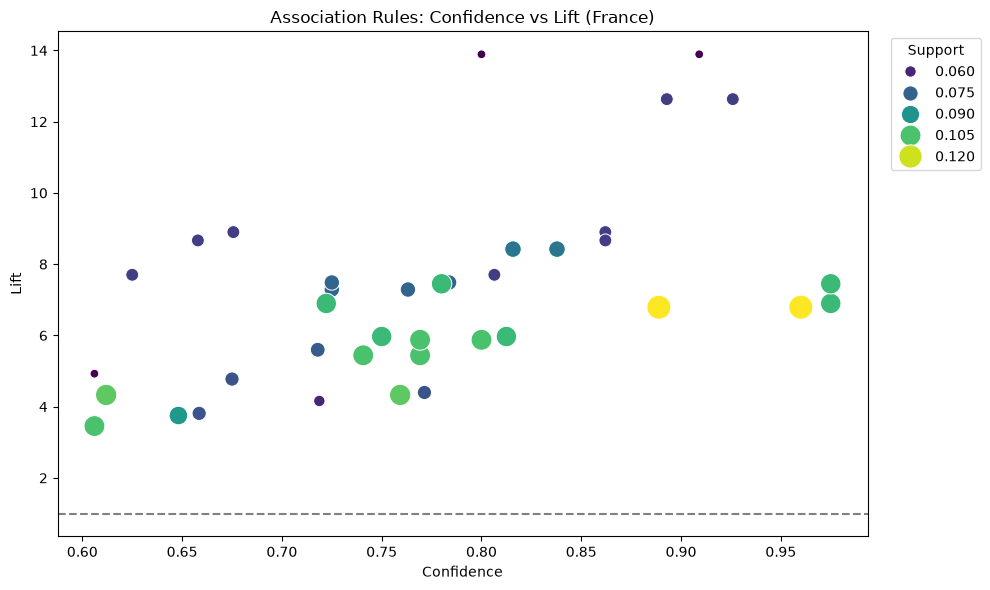

In [17]:
# Scatter plot of confidence vs lift, and check both algorithms gave identical rules

# Making a text version of the FP-Growth rules so they can be compared with the Apriori ones
# (Apriori's columns were already turned into text in the last step)
fp_pairs = set(zip(
    rules_fpgrowth['antecedents'].apply(lambda s: ' + '.join(sorted(s))),
    rules_fpgrowth['consequents'].apply(lambda s: ' + '.join(sorted(s)))
))

# Making the same (if-part, then-part) pairs from the Apriori rules
ap_pairs = set(zip(rules_apriori['antecedents'], rules_apriori['consequents']))

# True means both algorithms found exactly the same rules
print("Same rules from both algorithms:", fp_pairs == ap_pairs)

# Making a reasonably large figure
plt.figure(figsize=(10, 6))

# Drawing one dot per rule: x = confidence, y = lift.
# hue and size both show support, so bigger/darker dots are rules that happen more often.
sns.scatterplot(data=rules_apriori, x='confidence', y='lift',
                hue='support', size='support', sizes=(40, 300), palette='viridis')

# Drawing a dashed line at lift = 1: below this line, items are NOT really linked
plt.axhline(1, color='gray', linestyle='--')

# Title and axis labels so the chart explains itself
plt.title('Association Rules: Confidence vs Lift (France)')
plt.xlabel('Confidence')
plt.ylabel('Lift')

# Moving the legend outside the plot area so it doesn't cover any dots
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Support')

# Fitting everything in the figure and display it
plt.tight_layout()
plt.show()

## Step 4: Association Rules

**What I did:** I generated association rules from both the Apriori and the FP-Growth itemsets, keeping only rules with a **confidence of at least 0.6**. Both algorithms produced the same **38 rules**, and a direct check confirmed the rules were identical.

**How to read a rule:** each rule has the form "if a basket contains A, it also contains B", with three measures:
- **Support:** the share of all baskets that contain both A and B.
- **Confidence:** of the baskets containing A, the share that also contain B.
- **Lift:** how much more likely B is when A is present, compared with how often B is bought overall. A lift of 1 means no link, and above 1 means a real association.

**Key patterns found:**
- **Strongest links (highest lift):** skull paper cups and plates (lift 13.9), children's cutlery Dolly Girl and Spaceboy (lift 12.6), and the Bakelike alarm clocks in different colours (lift 8 to 9). These are matching sets that customers buy together far more than chance would suggest.
- **Most reliable rules (highest confidence):** baskets with the red retrospot napkins and the spotty plates or cups contain the third item 97.5% of the time, and the spotty plates lead to the spotty cups 96% of the time, in about 12.6% of all baskets.
- **Every rule has a lift well above 1** (the lowest is about 3.5), so these are genuine associations and not just popular items appearing together.

**What the scatter plot shows:** all 38 rules sit well above the dashed lift = 1 line. The highest-lift rules (lift 12 to 14) have small dots, meaning they are strongly linked but happen in only about 5 to 7% of baskets. The large yellow dots are common rules (support about 0.12) with very high confidence (0.89 to 0.96). In general, the rarer a rule is, the higher its lift tends to be.

**How a store could use this:** the matched sets (party supplies, children's cutlery, alarm clocks) are good candidates for bundles, "frequently bought together" suggestions, or placing the items side by side.

In [18]:
# Summary comparison of Apriori vs FP-Growth, plus the most reliable rules

# Building a small table that puts the two algorithms side by side.
# Each number comes from a result we already calculated in earlier steps.
comparison = pd.DataFrame({
    'Algorithm': ['Apriori', 'FP-Growth'],
    'Min support': [min_support, min_support],
    'Frequent itemsets': [len(frequent_apriori), len(frequent_fpgrowth)],
    'Rules (confidence >= 0.6)': [len(rules_apriori), len(rules_fpgrowth)],
    'Avg time over 20 runs (s)': [round(apriori_avg, 4), round(fpgrowth_avg, 4)]
})

# Showing the comparison table
print(comparison.to_string(index=False))

# Say which algorithm was faster in this experiment, and by what factor
faster = 'Apriori' if apriori_avg < fpgrowth_avg else 'FP-Growth'
ratio = max(apriori_avg, fpgrowth_avg) / min(apriori_avg, fpgrowth_avg)
print(f"\nFaster on this dataset: {faster} (about {ratio:.2f}x faster)")

# Showing the 5 most reliable rules (highest confidence) with their support and lift.
# These are the big dots on the right side of the scatter plot.
print("\nTop 5 rules by confidence:")
rules_apriori.sort_values('confidence', ascending=False)[
    ['antecedents', 'consequents', 'support', 'confidence', 'lift']
].head(5)

Algorithm  Min support  Frequent itemsets  Rules (confidence >= 0.6)  Avg time over 20 runs (s)
  Apriori         0.05                113                         38                     0.0215
FP-Growth         0.05                113                         38                     0.0337

Faster on this dataset: Apriori (about 1.57x faster)

Top 5 rules by confidence:


,antecedents,consequents,support,confidence,lift
34,SET/20 RED RETROSPOT PAPER NAPKINS + SET/6 RED...,SET/6 RED SPOTTY PAPER PLATES,0.102094,0.975000,7.449000
32,SET/20 RED RETROSPOT PAPER NAPKINS + SET/6 RED...,SET/6 RED SPOTTY PAPER CUPS,0.102094,0.975000,6.897222
21,SET/6 RED SPOTTY PAPER PLATES,SET/6 RED SPOTTY PAPER CUPS,0.125654,0.960000,6.791111
7,CHILDRENS CUTLERY SPACEBOY,CHILDRENS CUTLERY DOLLY GIRL,0.065445,0.925926,12.632275
10,PACK OF 6 SKULL PAPER PLATES,PACK OF 6 SKULL PAPER CUPS,0.052356,0.909091,13.890909


## Step 5: Comparative Analysis

### Apriori vs FP-Growth
Both algorithms were run on the France subset of the Online Retail dataset (382 baskets, 1,560 products) with the same minimum support of 0.05. They produced **identical results**: 113 frequent itemsets (76 single items, 34 pairs, 3 triples) and, at a confidence threshold of 0.6, the same 38 association rules.

| Algorithm | Frequent itemsets | Rules | Avg time (20 runs) |
|-----------|------------------|-------|--------------------|
| Apriori   | 113              | 38    | 0.0215 s           |
| FP-Growth | 113              | 38    | 0.0337 s           |

### Which was faster, and why
**Apriori was faster on this dataset (about 1.57x).** This is the opposite of what is usually expected, but it makes sense for this data. FP-Growth first has to build a compressed tree of all the baskets, and that setup has a fixed cost. FP-Growth's main advantage is that it avoids repeatedly scanning the data and generating huge numbers of candidate itemsets, but with only 382 baskets and a fairly high support threshold, Apriori has very few candidates to check, so there was little for FP-Growth to save. FP-Growth is expected to pull ahead with much larger datasets or lower support thresholds, which I did not test here. The differences are also tiny in absolute terms (hundredths of a second).

### Key insights from the rules
- The strongest links by lift are matched sets: skull paper cups and plates (lift 13.9), children's cutlery Dolly Girl and Spaceboy (lift 12.6), and the Bakelike alarm clocks in different colours (lift 8 to 9).
- The most reliable rules come from the red spotty party set: napkins plus plates or cups lead to the third item with 97.5% confidence.
- Every rule had a lift well above 1 (lowest about 3.5), so these are real associations rather than just popular items appearing together.

### Challenges and how I resolved them
- **Loading the data:** Python could not find the file because the path pointed to a folder named `data.csv` that contained the real `data.csv`. I used os.listdir to look inside it and then gave the full path to the file.
- **Postage dominated the results:** "POSTAGE" appeared in about 300 of 392 baskets, so it would have created meaningless rules. I removed postage and other non-product rows (fees, carriage, manual adjustments) and rebuilt the basket grid.
- **Dataset size:** Running on all countries (20,000+ baskets, 4,000+ products) would be slow, so I used only France.
- **Choosing the support threshold:** With few baskets, a high threshold finds almost nothing. I used 0.05, which gave a useful 113 itemsets.
- **Unreliable timing:** A single run took only about 0.03 s, which is too short to compare fairly, so I averaged 20 runs of each algorithm.